### Name :- Ankit Agrawal

### To implement a deep learning-based plant stress identification system for paddy leaves using five categories: Blast, Bacterial Leaf Blight (BLB), Healthy, Hispa, and Leaf Spot.

In [ ]:
## !pip install tensorflow numpy matplotlib seaborn scikit-learn pandas pillow

### Import libraries

In [5]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)
print("Python GPU Devices:", tf.config.list_physical_devices('GPU'))

All libraries imported successfully!
TensorFlow Version: 2.21.0
Python GPU Devices: []


###  Dataset paths

In [6]:
BASE_DIR = os.path.join(
    os.path.expanduser("~"),
    "Desktop",
    "DEEP LEARNING LAB",
    "Plant Stress Identification",
    "Dataset"
)

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "val")
TEST_DIR = os.path.join(BASE_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

print("Dataset Path:", BASE_DIR)

print("Train Folder Exists:", os.path.exists(TRAIN_DIR))
print("Validation Folder Exists:", os.path.exists(VAL_DIR))
print("Test Folder Exists:", os.path.exists(TEST_DIR))

Dataset Path: C:\Users\ANKIT AGRAWAL\Desktop\DEEP LEARNING LAB\Plant Stress Identification\Dataset
Train Folder Exists: True
Validation Folder Exists: True
Test Folder Exists: True


### Check dataset images and class distribution

In [7]:
def count_images(folder):

    extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

    counts = {}

    for class_name in sorted(os.listdir(folder)):

        class_path = os.path.join(folder, class_name)

        if os.path.isdir(class_path):

            images = [
                file for file in os.listdir(class_path)
                if file.lower().endswith(extensions)
            ]

            counts[class_name] = len(images)

    return counts


train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)
test_counts = count_images(TEST_DIR)

dataset_summary = pd.DataFrame({
    'Class': sorted(train_counts.keys()),
    'Training Images': [
        train_counts.get(c, 0) for c in sorted(train_counts)
    ],
    'Validation Images': [
        val_counts.get(c, 0) for c in sorted(train_counts)
    ],
    'Testing Images': [
        test_counts.get(c, 0) for c in sorted(train_counts)
    ]
})

display(dataset_summary)

print("\nTotal Training Images:", sum(train_counts.values()))
print("Total Validation Images:", sum(val_counts.values()))
print("Total Testing Images:", sum(test_counts.values()))

,Class,Training Images,Validation Images,Testing Images
0,BLB,308,88,44
1,Blast,328,93,48
2,healthy,325,93,47
3,hispa,298,85,43
4,leaf_spot,280,80,40



Total Training Images: 1539
Total Validation Images: 439
Total Testing Images: 222


### Load training, validation and testing datasets

In [8]:
class_names = sorted(train_counts.keys())

NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of Classes:", NUM_CLASSES)

assert NUM_CLASSES == 5, "Expected exactly 5 classes."

for folder in [VAL_DIR, TEST_DIR]:

    folder_classes = sorted([
        name for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
    ])

    assert folder_classes == class_names, (
        f"Class mismatch in {folder}"
    )


train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=False
)

print("All datasets loaded successfully!")

Classes: ['BLB', 'Blast', 'healthy', 'hispa', 'leaf_spot']
Number of Classes: 5
Found 1539 files belonging to 5 classes.
Found 439 files belonging to 5 classes.
Found 222 files belonging to 5 classes.
All datasets loaded successfully!


### Visualize sample images

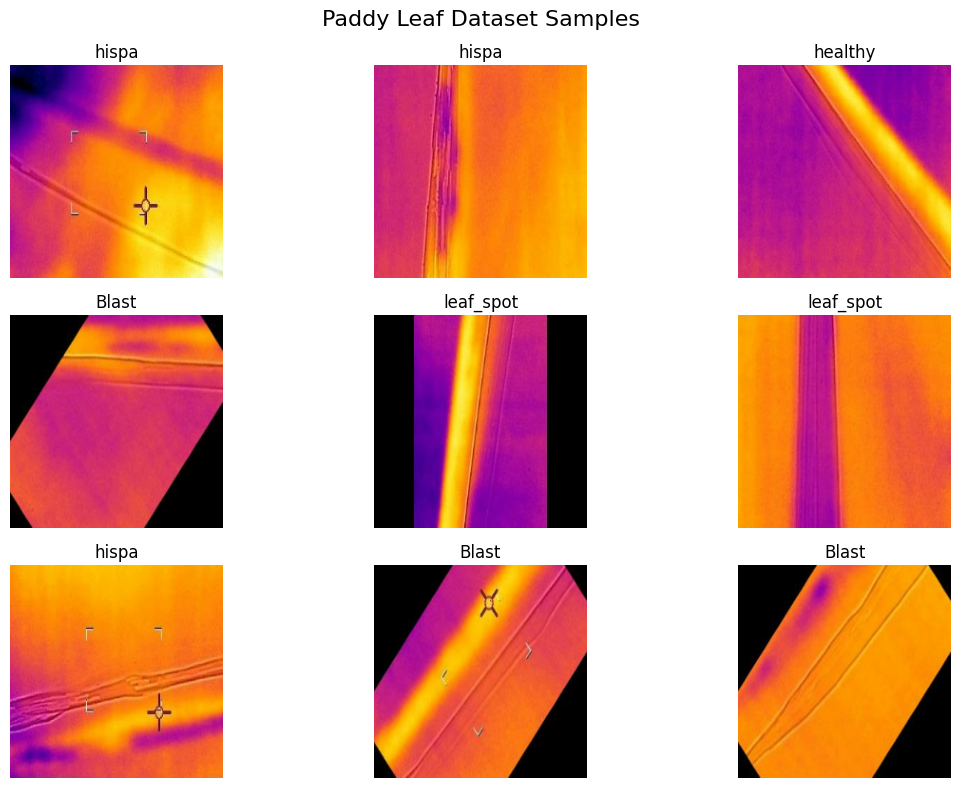

In [9]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(min(9, len(images))):

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[labels[i].numpy()]
        )

        plt.axis("off")

plt.suptitle("Paddy Leaf Dataset Samples", fontsize=16)

plt.tight_layout()
plt.show()

### Data preprocessing and augmentation

In [10]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.15),

    layers.RandomContrast(0.1)

], name="Data_Augmentation")


AUTOTUNE = tf.data.AUTOTUNE

# AlexNet dataset preprocessing
def prepare_alexnet(image, label):

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


alex_train = train_ds.map(
    prepare_alexnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

alex_val = val_ds.map(
    prepare_alexnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

alex_test = test_ds.map(
    prepare_alexnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)


# VGG16 dataset preprocessing
def prepare_vgg(image, label):

    image = tf.cast(image, tf.float32)

    image = preprocess_input(image)

    return image, label


vgg_train = train_ds.map(
    prepare_vgg,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

vgg_val = val_ds.map(
    prepare_vgg,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

vgg_test = test_ds.map(
    prepare_vgg,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)


print("Preprocessing completed successfully!")

Preprocessing completed successfully!


## Build and Train CNN Models
### Build AlexNet model

In [11]:
def build_alexnet():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        # Normalize input
        layers.Rescaling(1.0),

        # Data augmentation
        data_augmentation,

        # Convolution Layer 1
        layers.Conv2D(
            96,
            kernel_size=11,
            strides=4,
            activation='relu'
        ),

        layers.MaxPooling2D(
            pool_size=3,
            strides=2
        ),

        # Convolution Layer 2
        layers.Conv2D(
            256,
            kernel_size=5,
            padding='same',
            activation='relu'
        ),

        layers.MaxPooling2D(
            pool_size=3,
            strides=2
        ),

        # Convolution Layers 3, 4, 5
        layers.Conv2D(
            384, 3,
            padding='same',
            activation='relu'
        ),

        layers.Conv2D(
            384, 3,
            padding='same',
            activation='relu'
        ),

        layers.Conv2D(
            256, 3,
            padding='same',
            activation='relu'
        ),

        layers.MaxPooling2D(
            pool_size=3,
            strides=2
        ),

        # Feature extraction
        layers.GlobalAveragePooling2D(),

        # Fully connected layers
        layers.Dense(1024, activation='relu'),

        layers.Dropout(0.5),

        layers.Dense(512, activation='relu'),

        layers.Dropout(0.5),

        # Output layer
        layers.Dense(
            NUM_CLASSES,
            activation='softmax'
        )

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']

    )

    return model


alexnet_model = build_alexnet()

alexnet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Data_Augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 54, 54, 96)          │          34,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 26, 26, 96)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 256)         │         614,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 384)         │         885,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 12, 12, 384)         │       1,327,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 12, 12, 256)         │         884,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 5, 5, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1024)                │         263,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,537,733 (17.31 MB)

 Trainable params: 4,537,733 (17.31 MB)

 Non-trainable params: 0 (0.00 B)

### Train AlexNet model

In [12]:
early_stop_alex = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

alex_history = alexnet_model.fit(

    alex_train,

    validation_data=alex_val,

    epochs=EPOCHS,

    callbacks=[early_stop_alex]

)

alex_time = time.time() - start_time

print("\nAlexNet Training Completed!")

print(
    "Training Time:",
    round(alex_time, 2),
    "seconds"
)

Epoch 1/10


C:\Users\ANKIT AGRAWAL\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


97/97 ━━━━━━━━━━━━━━━━━━━━ 37s 356ms/step - accuracy: 0.2235 - loss: 1.6170 - val_accuracy: 0.3326 - val_loss: 1.5428
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 34s 352ms/step - accuracy: 0.3073 - loss: 1.5194 - val_accuracy: 0.3462 - val_loss: 1.4558
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 38s 396ms/step - accuracy: 0.3372 - loss: 1.4606 - val_accuracy: 0.3667 - val_loss: 1.3610
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 39s 400ms/step - accuracy: 0.3645 - loss: 1.4277 - val_accuracy: 0.4032 - val_loss: 1.3831
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 38s 396ms/step - accuracy: 0.4256 - loss: 1.3683 - val_accuracy: 0.4624 - val_loss: 1.3314
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 39s 400ms/step - accuracy: 0.4828 - loss: 1.2966 - val_accuracy: 0.4784 - val_loss: 1.2230
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 40s 411ms/step - accuracy: 0.4633 - loss: 1.2649 - val_accuracy: 0.5103 - val_loss: 1.2059
Epoch 8/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 41s 421ms/step - accuracy: 0.4945 - loss: 1.2307 - val_accuracy: 0.467

### Plot AlexNet training performance

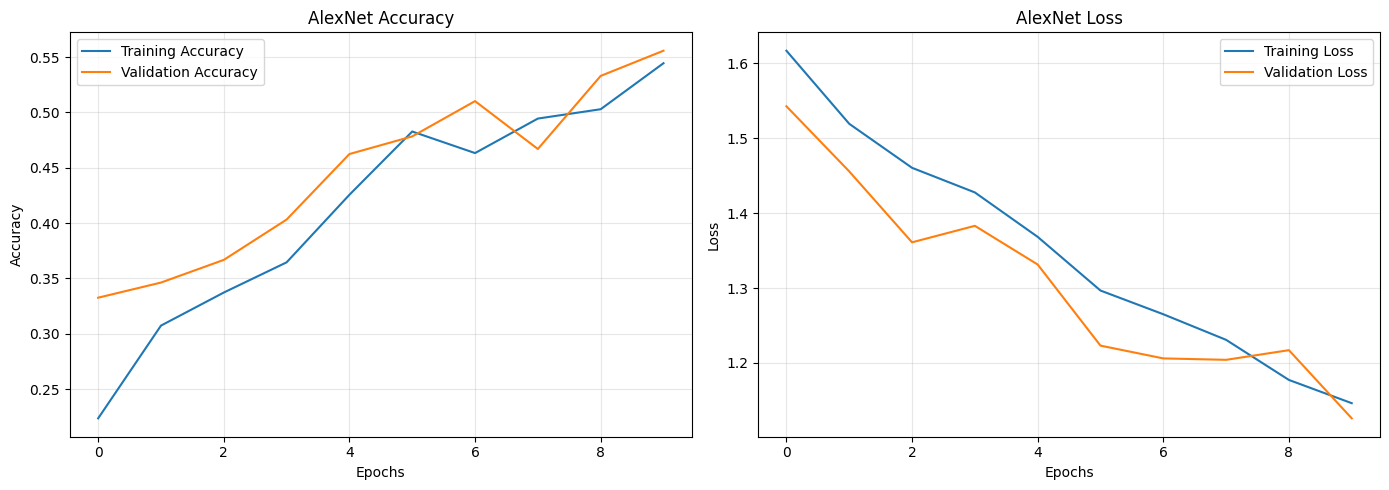

In [13]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    alex_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    alex_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("AlexNet Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    alex_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    alex_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("AlexNet Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)


plt.tight_layout()
plt.show()

### Build VGG16 model

In [14]:
def build_vgg16():

    base_model = VGG16(

        weights='imagenet',

        include_top=False,

        input_shape=(224, 224, 3)

    )

    # Freeze pretrained layers
    base_model.trainable = False

    inputs = layers.Input(
        shape=(224, 224, 3)
    )

    # Feature extraction
    x = base_model(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    # Custom classification head
    x = layers.Dense(
        256,
        activation='relu'
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']

    )

    return model


vgg_model = build_vgg16()

vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

### Train VGG16 model

In [15]:
early_stop_vgg = EarlyStopping(

    monitor='val_loss',

    patience=3,

    restore_best_weights=True

)

start_time = time.time()

vgg_history = vgg_model.fit(

    vgg_train,

    validation_data=vgg_val,

    epochs=EPOCHS,

    callbacks=[early_stop_vgg]

)

vgg_time = time.time() - start_time

print("\nVGG16 Training Completed!")

print(
    "Training Time:",
    round(vgg_time, 2),
    "seconds"
)

Epoch 1/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.3171 - loss: 3.5021 - val_accuracy: 0.6378 - val_loss: 1.0191
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step - accuracy: 0.4795 - loss: 2.0038 - val_accuracy: 0.6948 - val_loss: 0.8053
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - accuracy: 0.5419 - loss: 1.6286 - val_accuracy: 0.7380 - val_loss: 0.6930
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.6173 - loss: 1.1753 - val_accuracy: 0.7677 - val_loss: 0.6268
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.6537 - loss: 0.9964 - val_accuracy: 0.7836 - val_loss: 0.5689
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 227s 2s/step - accuracy: 0.7011 - loss: 0.8497 - val_accuracy: 0.8087 - val_loss: 0.5302
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.7186 - loss: 0.7673 - val_accuracy: 0.8246 - val_loss: 0.5013
Epoch 8/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 686s 7s/step - accuracy: 0.7557 - loss: 0.6613 - val_accuracy: 0.8337 - v

### Plot VGG16 training performance

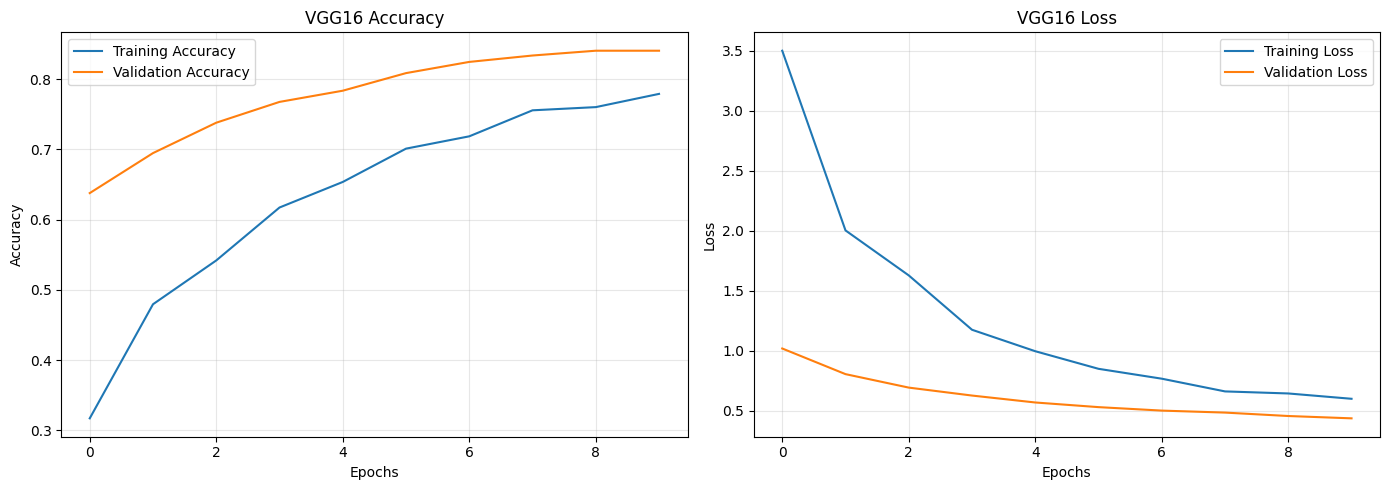

In [17]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    vgg_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    vgg_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("VGG16 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    vgg_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    vgg_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("VGG16 Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)


plt.tight_layout()
plt.show()

### . Evaluate model performance

In [18]:
def evaluate_model(model, dataset, model_name, training_time):

    y_true = np.concatenate([
        labels.numpy()
        for images, labels in dataset
    ])

    y_prob = model.predict(dataset)

    y_pred = np.argmax(y_prob, axis=1)

    # Performance metrics
    accuracy = accuracy_score(
        y_true, y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("\n==========", model_name, "==========")

    print("Accuracy:", round(accuracy, 4))

    print("Precision:", round(precision, 4))

    print("Recall:", round(recall, 4))

    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            target_names=class_names,
            zero_division=0
        )
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(model_name + " Confusion Matrix")

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.tight_layout()

    plt.show()

    return {

        'Model': model_name,

        'Accuracy': accuracy,

        'Precision': precision,

        'Recall': recall,

        'F1 Score': f1,

        'Training Time (seconds)': training_time

    }

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step

========== AlexNet ==========
Accuracy: 0.6036
Precision: 0.6612
Recall: 0.6036
F1 Score: 0.587

Classification Report:

              precision    recall  f1-score   support

         BLB       0.52      0.64      0.57        44
       Blast       0.79      0.62      0.70        48
     healthy       0.52      0.66      0.58        47
       hispa       0.60      0.84      0.70        43
   leaf_spot       0.90      0.23      0.36        40

    accuracy                           0.60       222
   macro avg       0.66      0.60      0.58       222
weighted avg       0.66      0.60      0.59       222



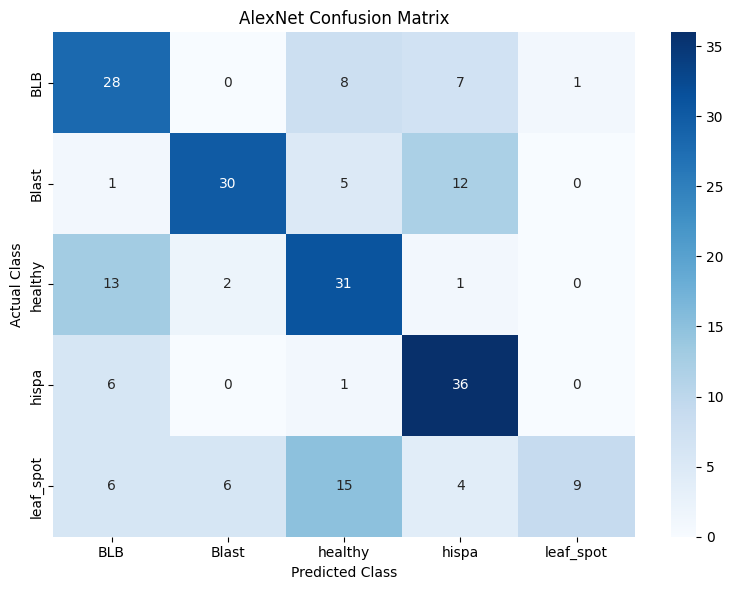

In [19]:
## Evaluate AlexNet
alex_results = evaluate_model(

    alexnet_model,

    alex_test,

    "AlexNet",

    alex_time

)

14/14 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step

========== VGG16 ==========
Accuracy: 0.9054
Precision: 0.9094
Recall: 0.9054
F1 Score: 0.9037

Classification Report:

              precision    recall  f1-score   support

         BLB       0.86      0.95      0.90        44
       Blast       0.95      0.75      0.84        48
     healthy       0.87      0.98      0.92        47
       hispa       0.98      0.98      0.98        43
   leaf_spot       0.90      0.88      0.89        40

    accuracy                           0.91       222
   macro avg       0.91      0.91      0.90       222
weighted avg       0.91      0.91      0.90       222



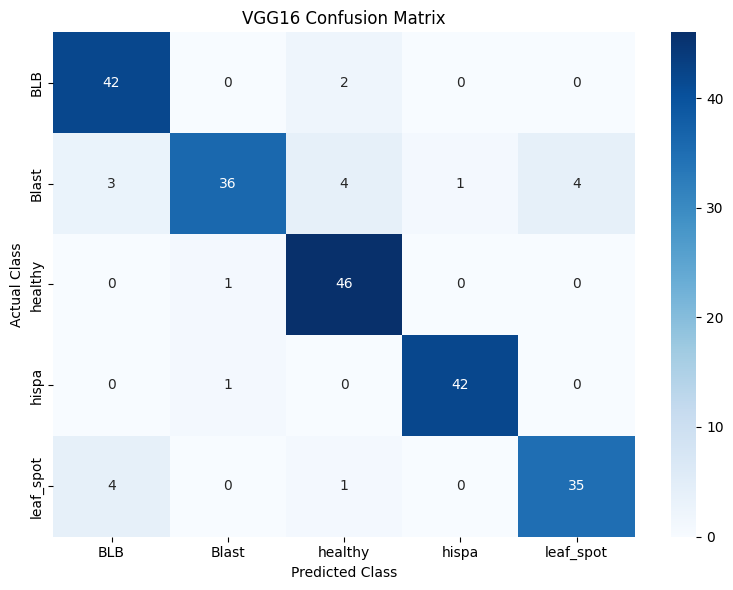

In [20]:
## Evaluate VGG16
vgg_results = evaluate_model(

    vgg_model,

    vgg_test,

    "VGG16",

    vgg_time

)

### Compare AlexNet and VGG16

In [21]:
comparison = pd.DataFrame([

    alex_results,

    vgg_results

])

print("FINAL MODEL COMPARISON")

display(
    comparison.style.format({

        'Accuracy': '{:.4f}',

        'Precision': '{:.4f}',

        'Recall': '{:.4f}',

        'F1 Score': '{:.4f}',

        'Training Time (seconds)': '{:.2f}'

    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (seconds)
0,AlexNet,0.6036,0.6612,0.6036,0.5870,386.04
1,VGG16,0.9054,0.9094,0.9054,0.9037,2696.28


### . Performance comparison visualization

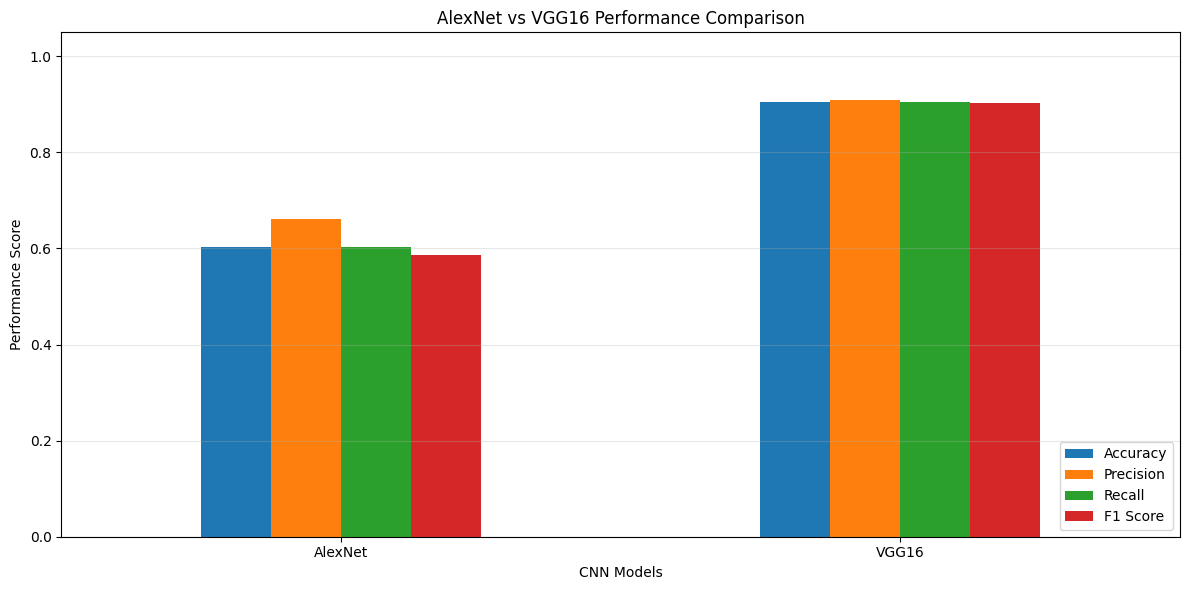

In [22]:
metrics = [

    'Accuracy',

    'Precision',

    'Recall',

    'F1 Score'

]

comparison.set_index('Model')[metrics].plot(

    kind='bar',

    figsize=(12, 6)

)

plt.title("AlexNet vs VGG16 Performance Comparison")

plt.xlabel("CNN Models")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

### Computational time comparison:

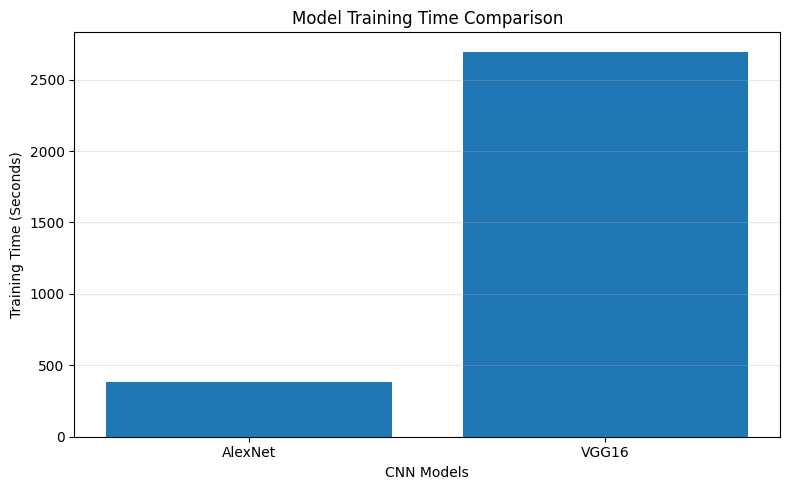

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(

    comparison['Model'],

    comparison['Training Time (seconds)']

)

plt.title("Model Training Time Comparison")

plt.xlabel("CNN Models")

plt.ylabel("Training Time (Seconds)")

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

### Paddy Leaf Image Prediction

Image Path: C:\Users\ANKIT AGRAWAL\Desktop\DEEP LEARNING LAB\Plant Stress Identification\Dataset\test\leaf_spot\thermalimage2i__rot90.jpg
Image Exists: True

Available Classes: ['BLB', 'Blast', 'healthy', 'hispa', 'leaf_spot']

Starting AlexNet Prediction...


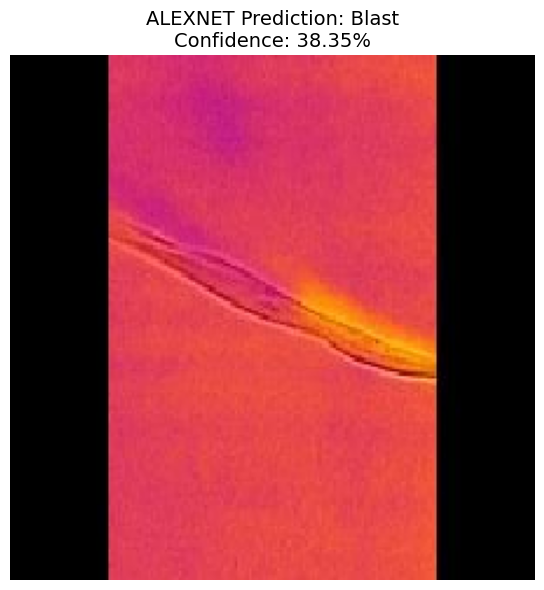


       PADDY LEAF CLASSIFICATION
Model: ALEXNET
Predicted Class: Blast
Confidence: 38.35 %

CLASS-WISE PROBABILITIES


,Class,Probability (%)
0,Blast,38.35%
1,healthy,32.45%
2,leaf_spot,25.52%
3,BLB,2.50%
4,hispa,1.19%


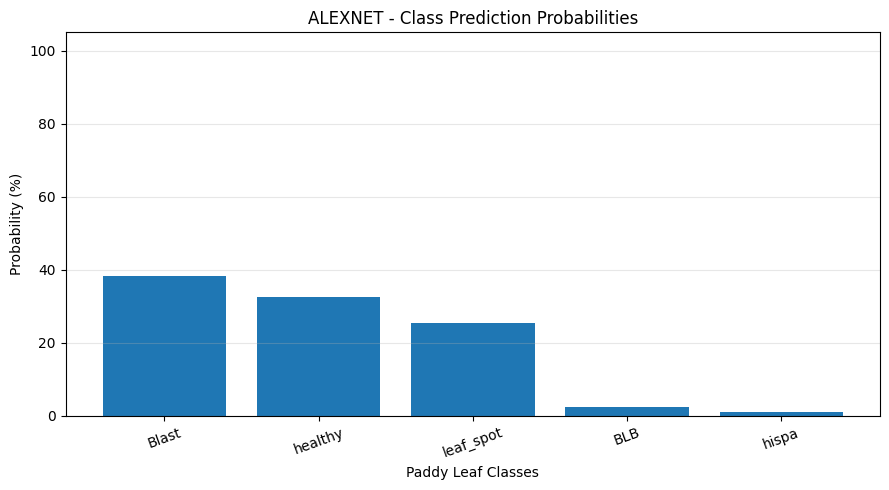


Starting VGG16 Prediction...


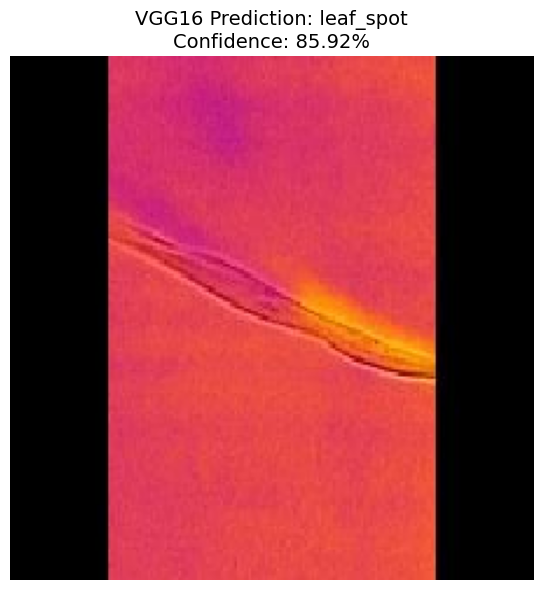


       PADDY LEAF CLASSIFICATION
Model: VGG16
Predicted Class: leaf_spot
Confidence: 85.92 %

CLASS-WISE PROBABILITIES


,Class,Probability (%)
0,leaf_spot,85.92%
1,healthy,8.54%
2,Blast,5.15%
3,BLB,0.37%
4,hispa,0.02%


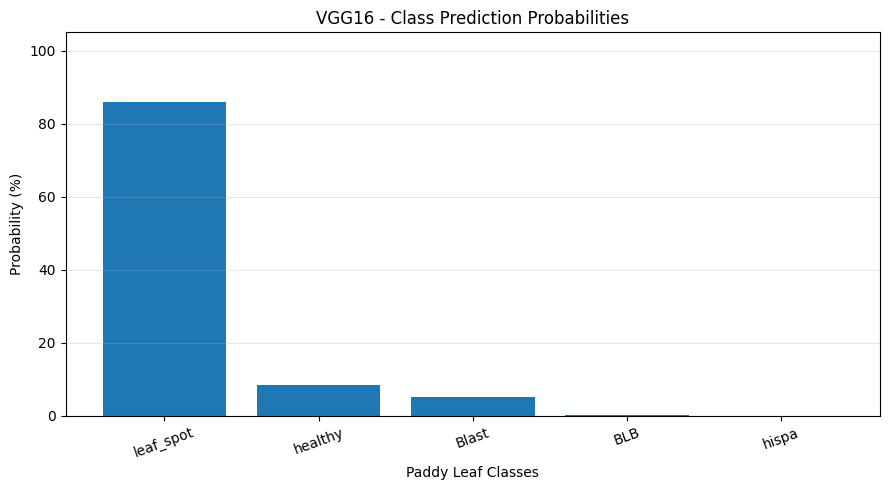


      FINAL MODEL PREDICTION


,Model,Predicted Class,Confidence (%)
0,ALEXNET,Blast,38.35%
1,VGG16,leaf_spot,85.92%



CLASS-WISE CONFIDENCE COMPARISON


,Class,AlexNet (%),VGG16 (%)
0,BLB,2.50%,0.37%
1,Blast,38.35%,5.15%
2,healthy,32.45%,8.54%
3,hispa,1.19%,0.02%
4,leaf_spot,25.52%,85.92%


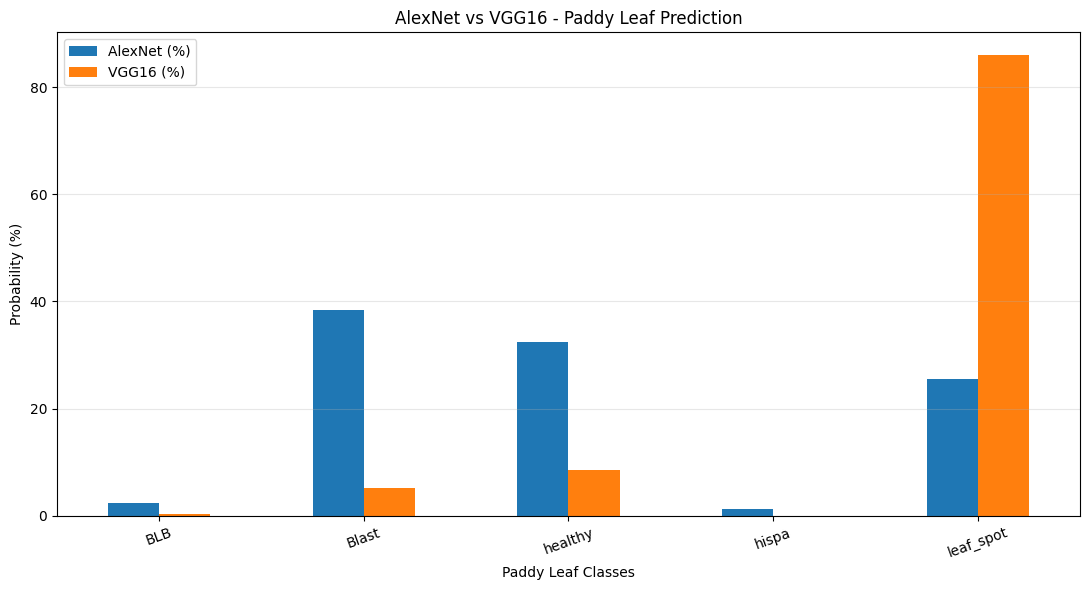


PADDY LEAF PREDICTION COMPLETED SUCCESSFULLY!


In [37]:
# ==========================================================
# PLANT STRESS IDENTIFICATION - PADDY LEAF PREDICTION
# Using AlexNet and VGG16
# ==========================================================

# 1. IMPORT LIBRARIES
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.applications.vgg16 import preprocess_input
from IPython.display import display


# ==========================================================
# 2. DEFINE DATASET AND IMAGE PATH
# ==========================================================

BASE_DIR = os.path.join(
    os.path.expanduser("~"),
    "Desktop",
    "DEEP LEARNING LAB",
    "Plant Stress Identification",
    "Dataset"
)

image_path = os.path.join(
    BASE_DIR,
    "test",
    "leaf_spot",
    "thermalimage2i__rot90.jpg"
)

print("Image Path:", image_path)
print("Image Exists:", os.path.isfile(image_path))


# ==========================================================
# 3. CHECK TRAINED MODELS AND CLASS NAMES
# ==========================================================

if 'alexnet_model' not in globals():
    raise NameError("AlexNet model not found. Train AlexNet first.")

if 'vgg_model' not in globals():
    raise NameError("VGG16 model not found. Train VGG16 first.")

if 'class_names' not in globals():
    raise NameError("Class names not found. Load the dataset first.")

if not os.path.isfile(image_path):
    raise FileNotFoundError("Selected paddy leaf image was not found.")


print("\nAvailable Classes:", class_names)


# ==========================================================
# 4. DEFINE PREDICTION FUNCTION
# ==========================================================

def predict_leaf(image_path, model, model_type):

    # Load image
    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    # Model-specific preprocessing
    if model_type.lower() == "alexnet":

        img_array = img_array / 255.0

    elif model_type.lower() == "vgg16":

        img_array = preprocess_input(
            img_array.astype(np.float32)
        )

    else:

        raise ValueError("Invalid model type!")

    # Predict
    predictions = model.predict(
        img_array,
        verbose=0
    )

    predicted_index = np.argmax(predictions[0])

    predicted_class = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    # Display original image and result
    plt.figure(figsize=(7, 6))

    plt.imshow(img)

    plt.title(
        f"{model_type.upper()} Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=14
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # Create probability table
    results = pd.DataFrame({

        "Class": class_names,

        "Probability (%)": predictions[0] * 100

    })

    results = results.sort_values(
        by="Probability (%)",
        ascending=False
    ).reset_index(drop=True)

    # Display result
    print("\n======================================")
    print("       PADDY LEAF CLASSIFICATION")
    print("======================================")

    print("Model:", model_type.upper())
    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

    print("\nCLASS-WISE PROBABILITIES")

    display(
        results.style.format({
            "Probability (%)": "{:.2f}%"
        })
    )

    # Probability graph
    plt.figure(figsize=(9, 5))

    plt.bar(
        results["Class"],
        results["Probability (%)"]
    )

    plt.title(
        f"{model_type.upper()} - Class Prediction Probabilities"
    )

    plt.xlabel("Paddy Leaf Classes")
    plt.ylabel("Probability (%)")

    plt.ylim(0, 105)

    plt.xticks(rotation=20)

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

    return {
        "Model": model_type.upper(),
        "Predicted Class": predicted_class,
        "Confidence (%)": confidence,
        "Probabilities": predictions[0].copy()
    }


# ==========================================================
# 5. PREDICTION USING ALEXNET
# ==========================================================

print("\nStarting AlexNet Prediction...")

alex_result = predict_leaf(
    image_path,
    alexnet_model,
    "alexnet"
)


# ==========================================================
# 6. PREDICTION USING VGG16
# ==========================================================

print("\nStarting VGG16 Prediction...")

vgg_result = predict_leaf(
    image_path,
    vgg_model,
    "vgg16"
)


# ==========================================================
# 7. COMPARE BOTH MODELS
# ==========================================================

comparison = pd.DataFrame({

    "Model": [
        alex_result["Model"],
        vgg_result["Model"]
    ],

    "Predicted Class": [
        alex_result["Predicted Class"],
        vgg_result["Predicted Class"]
    ],

    "Confidence (%)": [
        alex_result["Confidence (%)"],
        vgg_result["Confidence (%)"]
    ]

})

print("\n======================================")
print("      FINAL MODEL PREDICTION")
print("======================================")

display(
    comparison.style.format({
        "Confidence (%)": "{:.2f}%"
    })
)


# ==========================================================
# 8. COMPARE CLASS-WISE CONFIDENCE
# ==========================================================

probability_comparison = pd.DataFrame({

    "Class": class_names,

    "AlexNet (%)": alex_result["Probabilities"] * 100,

    "VGG16 (%)": vgg_result["Probabilities"] * 100

})

print("\nCLASS-WISE CONFIDENCE COMPARISON")

display(
    probability_comparison.style.format({
        "AlexNet (%)": "{:.2f}%",
        "VGG16 (%)": "{:.2f}%"
    })
)


# ==========================================================
# 9. VISUALIZE MODEL COMPARISON
# ==========================================================

probability_comparison.set_index("Class").plot(

    kind="bar",

    figsize=(11, 6)

)

plt.title("AlexNet vs VGG16 - Paddy Leaf Prediction")

plt.xlabel("Paddy Leaf Classes")

plt.ylabel("Probability (%)")

plt.xticks(rotation=20)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


print("\nPADDY LEAF PREDICTION COMPLETED SUCCESSFULLY!")

In [38]:
prediction_comparison = pd.DataFrame({

    'Model': ['AlexNet', 'VGG16'],

    'Predicted Class': [
        alex_prediction,
        vgg_prediction
    ]

})

print("PADDY LEAF PREDICTION COMPARISON")

display(prediction_comparison)

PADDY LEAF PREDICTION COMPARISON


,Model,Predicted Class
0,AlexNet,Blast
1,VGG16,leaf_spot


In [39]:
# Actual class from dataset folder
actual_class = "leaf_spot"

# Compare predictions
final_check = pd.DataFrame({

    "Model": ["AlexNet", "VGG16"],

    "Actual Class": [
        actual_class,
        actual_class
    ],

    "Predicted Class": [
        alex_result["Predicted Class"],
        vgg_result["Predicted Class"]
    ],

    "Correct Prediction": [
        alex_result["Predicted Class"] == actual_class,
        vgg_result["Predicted Class"] == actual_class
    ]

})

display(final_check)

,Model,Actual Class,Predicted Class,Correct Prediction
0,AlexNet,leaf_spot,Blast,False
1,VGG16,leaf_spot,leaf_spot,True


### Save all project results

In [40]:
import os
import json

RESULT_DIR = "Plant_Stress_Results"

os.makedirs(RESULT_DIR, exist_ok=True)

# Save models
alexnet_model.save(
    os.path.join(RESULT_DIR, "AlexNet.keras")
)

vgg_model.save(
    os.path.join(RESULT_DIR, "VGG16.keras")
)

# Save comparison
comparison.to_csv(
    os.path.join(RESULT_DIR, "Model_Comparison.csv"),
    index=False
)

# Save prediction comparison
final_check.to_csv(
    os.path.join(RESULT_DIR, "Prediction_Results.csv"),
    index=False
)

# Save class names
with open(
    os.path.join(RESULT_DIR, "class_names.json"),
    "w"
) as f:

    json.dump(class_names, f, indent=4)

print("All project results saved successfully!")

All project results saved successfully!


## Final project conclusion
## Conclusion – Plant Stress Identification Using CNN
## The experiment successfully implemented a deep learning-based Plant Stress Identification system for paddy leaves using five categories: Blast, Bacterial Leaf Blight (BLB), Healthy, Hispa, and Leaf Spot.
## Two CNN architectures, AlexNet and VGG16, were implemented and evaluated. AlexNet was used as a baseline CNN model, while VGG16 utilized pretrained ImageNet weights for deep feature extraction.

## Both models were tested using the same testing dataset. Their performance was compared using Accuracy, Precision, Recall, F1-score, confusion matrices, and computational training time.
## The trained models were also used to predict the category of a new paddy leaf image. The experiment demonstrates how deep learning and CNN architectures can be applied to automated paddy leaf classification. The better-performing architecture should be selected based on its overall test-set evaluation results.